# **Fraud Strategy Advsiory Agreement**

## 1. Setup & Data Extraction

In [ ]:
%pip install -e "/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement"

In [2]:
# Import 3rd Party Libraries 
import pandas as pd
from fraud_strategy.helpers import check_non_null_percentage

In [3]:
import sys
print(sys.executable)

/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement/.venv/bin/python


In [4]:
import importlib.util

print("psycopg:", importlib.util.find_spec("psycopg"))
print("sqlalchemy:", importlib.util.find_spec("sqlalchemy"))

psycopg: ModuleSpec(name='psycopg', loader=<_frozen_importlib_external.SourceFileLoader object at 0x112b830b0>, origin='/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement/.venv/lib/python3.14/site-packages/psycopg/__init__.py', submodule_search_locations=['/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement/.venv/lib/python3.14/site-packages/psycopg'])
sqlalchemy: ModuleSpec(name='sqlalchemy', loader=<_frozen_importlib_external.SourceFileLoader object at 0x112b82f90>, origin='/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement/.venv/lib/python3.14/site-packages/sqlalchemy/__init__.py', submodule_search_locations=['/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement/.venv/lib/python3.14/site-packages/sqlalchemy'])


In [5]:
import psycopg
import sqlalchemy

print(psycopg.__version__)
print(sqlalchemy.__version__)

3.3.6
2.0.54


### Importing applications data from postgresql (applications table)

In [6]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine(
    "postgresql+psycopg://spencerwillard@localhost:5432/fraud_strategy"
)

In [7]:
query = ("""
SELECT application_id,
       application_date,
       third_party_fraud_score,
       channel
FROM applications; 
""")

query_results = pd.read_sql(query, engine)

## 2. Data Validation & Cleaning

### Checking data cleanliness

In [8]:
print(f"Number of Rows: {query_results.shape[0]}")
print(f"Number of Columns: {query_results.shape[1]}")

Number of Rows: 775390
Number of Columns: 4


In [9]:
print(f"{query_results.columns}\n")


for number, column in enumerate (query_results.columns, start=1):
    print(f"Column #{number}:  {column}")


Index(['application_id', 'application_date', 'third_party_fraud_score',
       'channel'],
      dtype='str')

Column #1:  application_id
Column #2:  application_date
Column #3:  third_party_fraud_score
Column #4:  channel


In [10]:
# Create raw_df for data cleaning
applications = query_results.copy()

In [11]:
applications.shape

(775390, 4)

In [12]:
applications.info()

<class 'pandas.DataFrame'>
RangeIndex: 775390 entries, 0 to 775389
Data columns (total 4 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   application_id           775390 non-null  str           
 1   application_date         775390 non-null  datetime64[us]
 2   third_party_fraud_score  775390 non-null  int64         
 3   channel                  772898 non-null  str           
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 34.7 MB


**Data Health Findings** 
- application_id is a string. Probably should stay that way in case characters are ever added. 
- application_id is a unique value
- Digital is the largest channel value at approximately 65.6%
- 2,492 rows have a missing channel value (0.321%)
- replaced rows with "missing channel" for NaN values in channel 

In [13]:
applications.dtypes

application_id                        str
application_date           datetime64[us]
third_party_fraud_score             int64
channel                               str
dtype: object

In [14]:
applications.head()

,application_id,application_date,third_party_fraud_score,channel
0,10000001,2025-04-01 00:07:03,430,digital
1,10000002,2025-04-01 00:11:07,525,digital
2,10000003,2025-04-01 00:22:56,61,digital
3,10000004,2025-04-01 00:37:46,215,partner
4,10000005,2025-04-01 00:38:37,99,digital


In [15]:
applications.sample(5)

,application_id,application_date,third_party_fraud_score,channel
115335,10115336,2025-06-14 20:29:11,70,digital
144436,10144437,2025-07-03 12:55:36,532,digital
705745,10705746,2026-07-15 20:36:01,109,digital
57113,10057114,2025-05-07 18:21:49,400,digital
362929,10362930,2025-11-28 12:12:20,362,branch


In [16]:
# Since application_id is a string, removing any potential whitespace to avoide issue later on 
applications["application_id"] = applications["application_id"].str.strip()

In [17]:
applications["application_id"].sample(10)

459521    10459522
266322    10266323
307544    10307545
748471    10748472
334730    10334731
715204    10715205
770286    10770287
232106    10232107
230606    10230607
774695    10774696
Name: application_id, dtype: str

In [18]:
# Is application_id unique? 
print(f"Non Null Values in application_id: {applications["application_id"].count()}")

Non Null Values in application_id: 775390


In [19]:
# Confirmed application_id is unique
applications["application_id"].is_unique

True

In [20]:
# Confirmed application_id is unique
applications["application_id"].nunique()

775390

In [21]:
# Check breakdown of channel column
print(applications["channel"].value_counts(dropna=False))

print(f"\nPercentages Below")

print(applications["channel"].value_counts(normalize=True, dropna=False).mul(100).round(3))



channel
digital    508588
partner    137486
branch     126824
NaN          2492
Name: count, dtype: int64

Percentages Below
channel
digital    65.591
partner    17.731
branch     16.356
NaN         0.321
Name: proportion, dtype: float64


In [22]:
applications.loc[applications["channel"].isna()].head(10)

,application_id,application_date,third_party_fraud_score,channel
102,10000103,2025-04-01 07:01:19,2,NaN
1055,10001056,2025-04-01 14:56:32,116,NaN
1057,10001058,2025-04-01 14:56:46,79,NaN
1302,10001303,2025-04-01 16:52:21,238,NaN
1371,10001372,2025-04-01 17:33:18,137,NaN
1437,10001438,2025-04-01 18:28:01,714,NaN
1482,10001483,2025-04-01 19:06:53,297,NaN
1526,10001527,2025-04-01 19:48:20,137,NaN
1922,10001923,2025-04-02 08:47:56,175,NaN
2084,10002085,2025-04-02 10:29:21,530,NaN


In [23]:
# channel is the only column with missing values
applications.isna().sum()

application_id                0
application_date              0
third_party_fraud_score       0
channel                    2492
dtype: int64

In [24]:
# We know there a clean values in channel 
applications.loc[applications["channel"].notna()].head(10)

,application_id,application_date,third_party_fraud_score,channel
0,10000001,2025-04-01 00:07:03,430,digital
1,10000002,2025-04-01 00:11:07,525,digital
2,10000003,2025-04-01 00:22:56,61,digital
3,10000004,2025-04-01 00:37:46,215,partner
4,10000005,2025-04-01 00:38:37,99,digital
5,10000006,2025-04-01 00:54:32,143,digital
6,10000007,2025-04-01 01:17:12,504,digital
7,10000008,2025-04-01 01:20:39,577,digital
8,10000009,2025-04-01 01:32:28,86,partner
9,10000010,2025-04-01 01:43:15,412,digital


In [25]:
applications["channel"].value_counts(dropna=False)

channel
digital    508588
partner    137486
branch     126824
NaN          2492
Name: count, dtype: int64

In [26]:
# Clean up channel column 
applications["channel"] = applications["channel"].str.strip().str.lower()

In [27]:
applications["channel"] = applications["channel"].fillna("missing channel")

In [28]:
applications["channel"].value_counts()

channel
digital            508588
partner            137486
branch             126824
missing channel      2492
Name: count, dtype: int64

In [29]:
# Lets start loooking for duplicate values
# Triple check application_id for uniqueness
print(f"Is application_id unique? {applications["application_id"].is_unique}\n")
print(f"Number of unique application_id values: {applications["application_id"].nunique()}")


Is application_id unique? True

Number of unique application_id values: 775390


In [30]:
applications.duplicated(subset=["application_id"]).sum()

np.int64(0)

In [31]:
# Lets check if there are any duplicate rows matching all columns. Since application_id is unique and I would expect the rest of the columns to have duplicates. 
print(f"How many exact duplicate rows do we have? {applications.duplicated().sum()}")

How many exact duplicate rows do we have? 0


In [32]:
# Check monthly ditribution for application_date
print(f"Earliest Date Value: {applications["application_date"].min()}")
print(f"Latest Date Value: {applications["application_date"].max()}\n")

print((applications["application_date"]
    .dt.to_period("M")
    .value_counts(dropna=False)
    .sort_index()))

Earliest Date Value: 2025-04-01 00:07:03
Latest Date Value: 2026-08-31 23:50:51

application_date
2025-04    46193
2025-05    46887
2025-06    47190
2025-07    46153
2025-08    44512
2025-09    45194
2025-10    46864
2025-11    43721
2025-12    44922
2026-01    44314
2026-02    45204
2026-03    45904
2026-04    45810
2026-05    45949
2026-06    45137
2026-07    46206
2026-08    45230
Freq: M, Name: count, dtype: int64


In [33]:
# Check third_party_fraud_score min and max values
print(f"Min Score Value: {applications["third_party_fraud_score"].min()}")
print(f"Max Score Value: {applications["third_party_fraud_score"].max()}\n")

applications["third_party_fraud_score"].sample(10)


Min Score Value: 0
Max Score Value: 999



376935    261
359687     55
189703    218
455632     83
711479    610
27185     106
224181    275
161681     32
99073     763
465236    343
Name: third_party_fraud_score, dtype: int64

## 3. Application Population Profiling

In [34]:
applications.groupby("channel").size()

channel
branch             126824
digital            508588
missing channel      2492
partner            137486
dtype: int64

In [35]:
applications.groupby("channel")["third_party_fraud_score"].count()

channel
branch             126824
digital            508588
missing channel      2492
partner            137486
Name: third_party_fraud_score, dtype: int64

In [36]:
applications.groupby("channel")["third_party_fraud_score"].mean().round(2)

channel
branch             235.92
digital            261.27
missing channel    258.16
partner            279.55
Name: third_party_fraud_score, dtype: float64

In [37]:
applications.groupby("channel", dropna=False).agg(
    application_count=("application_id", "count"), 
    scored_applications=("third_party_fraud_score", "count"), 
    avg_fraud_score=("third_party_fraud_score", "mean")
).reset_index()

,channel,application_count,scored_applications,avg_fraud_score
0,branch,126824,126824,235.919195
1,digital,508588,508588,261.265219
2,missing channel,2492,2492,258.157303
3,partner,137486,137486,279.553475


Profiling conclusion: The application dataset is structurally suitable for strategy evaluation. Application IDs are unique, score and date fields are complete and appropriately typed, score values fall within the expected 0–999 range, and missing channel values represent a small portion of the population and have been retained as a separate category.

## 4. Current Strategy Evaluation

In [38]:
# Check how many applications score >= 700 for the "third_party_fraud_score"
flagged_apps = ((applications["third_party_fraud_score"] >= 700).sum())
print(f"Applications Scored >= 700: {flagged_apps:,}")


Applications Scored >= 700: 43,736


In [39]:
# Count total scored applications
total_apps = applications["third_party_fraud_score"].size
print(f"Total Applications: {total_apps:,}")

Total Applications: 775,390


In [40]:
high_scoring_ratio = flagged_apps / total_apps


high_scoring_percentage = high_scoring_ratio * 100

print(f"% of Applications Flagged for Manual Review (>= 700): {high_scoring_percentage:.2f}%")

# high_scoring_percent = high_scoring_ratio.mul(100)
# print(f"Percentage of Applications Flagged for Manual Review {high_scoring_percentage}")

% of Applications Flagged for Manual Review (>= 700): 5.64%


In [41]:
# Calculate number of reviews × cost per review = total review cost
cost_of_manual_review = 12
total_review_cost = flagged_apps * cost_of_manual_review
print(f"Total Review Cost: ${total_review_cost:,}")

Total Review Cost: $524,832


In [42]:
applications.columns

Index(['application_id', 'application_date', 'third_party_fraud_score',
       'channel'],
      dtype='str')

In [43]:
# Lets figure out the the review rate compares across channels 

channel_summary = (
    applications.groupby("channel")
    .agg(application_count=("application_id", "count"),
        high_scoring_count=("third_party_fraud_score", lambda x: (x >= 700).sum())
        
        )
)
channel_summary

,application_count,high_scoring_count
channel,,
branch,126824,5028
digital,508588,29083
missing channel,2492,155
partner,137486,9470


In [44]:
# Create review_rate column (shown in decimals)
channel_summary["review_rate (d)"] = channel_summary["high_scoring_count"] / channel_summary["application_count"]

# Create new columns that shows cost of review for each channel 
channel_summary["review_cost_per_channel ($)"] = channel_summary["high_scoring_count"] * cost_of_manual_review

# Display the channel_summary chart
channel_summary


,application_count,high_scoring_count,review_rate (d),review_cost_per_channel ($)
channel,,,,
branch,126824,5028,0.039645,60336
digital,508588,29083,0.057184,348996
missing channel,2492,155,0.062199,1860
partner,137486,9470,0.068880,113640


**Channel Findings:** Partner has the highest review rate, while digital drives the majority of review volume and associated cost due to its substantially larger application volume.

In [45]:
# Create a new clean application_month column since we'll need it frequently. 
applications["application_month"] = applications["application_date"].dt.to_period("M")

In [46]:
monthly_summary = (
    applications.groupby("application_month", as_index=False)
    .agg(application_count=("application_id", "count"),
         high_scoring_count=("third_party_fraud_score", (lambda x: (x >= 700).sum()))
    )
    
)

monthly_summary["review_rate (d)"] = monthly_summary["high_scoring_count"] / monthly_summary["application_count"]

monthly_summary["review_cost_per_month ($)"] = monthly_summary["high_scoring_count"] * cost_of_manual_review

# Display monthly_summary table
monthly_summary

,application_month,application_count,high_scoring_count,review_rate (d),review_cost_per_month ($)
0,2025-04,46193,2464,0.053341,29568
1,2025-05,46887,2602,0.055495,31224
2,2025-06,47190,2519,0.053380,30228
3,2025-07,46153,2565,0.055576,30780
4,2025-08,44512,2403,0.053985,28836
5,2025-09,45194,2542,0.056246,30504
6,2025-10,46864,2585,0.055160,31020
7,2025-11,43721,2399,0.054871,28788
8,2025-12,44922,2476,0.055118,29712
9,2026-01,44314,2527,0.057025,30324


In [47]:
# Lets import the matplotlib 3rd party library to use for visuals
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates

In [48]:
monthly_summary.columns

Index(['application_month', 'application_count', 'high_scoring_count',
       'review_rate (d)', 'review_cost_per_month ($)'],
      dtype='str')

In [49]:
pd.set_option("display.max_columns", 100)

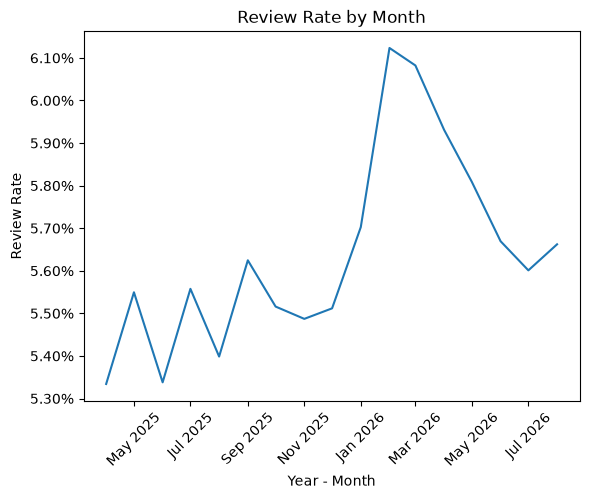

In [50]:
plt.plot(
    monthly_summary["application_month"].dt.to_timestamp(),
    monthly_summary["review_rate (d)"]
)

plt.title("Review Rate by Month")
plt.xlabel("Year - Month")
plt.ylabel("Review Rate")

plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)
plt.xticks(rotation=45)

plt.show()

**Monthly Findings**: 
Manual review volume increased in early 2026, with review rates peaking around 6.1% in February and March compared with roughly 5.3–5.6% through much of 2025. This increased operational cost modestly, but review volume alone cannot explain the reported increase in fraud losses. Outcome data is required to evaluate whether reviewed applications ultimately resulted in fraud and whether the current 700 threshold is effectively separating fraudulent from legitimate applicants.

## 5. Outcome Data & Population Definition

**Tracking changes made to outcomes dataframe** 
- changed application_id from an integer to a string value
- changed following columnes to datetime
    - outcome_as_of_date
    - booking_date
    - outcome_observation_end_date
    - review_started_date
    - review_completed_date



In [51]:
outcome_file_path = "/Users/spencerwillard/code/local/portfolio-level-projects/fraud_strategy_advisory_engagement/data/raw/outcomes.csv"
outcomes = pd.read_csv(outcome_file_path)

In [52]:

print("--From applications table--")
print(f"Number of Rows: {query_results.shape[0]:,}")
print(f"Number of Columns: {query_results.shape[1]:,}\n")

print("--From outcomes.csv--")
print(f"Number of Rows: {outcomes.shape[0]:,}")
print(f"Number of Columns: {outcomes.shape[1]:,}")

print(f"""\nOverall the number of rows looks correct but will need to confirm explicitly""")


--From applications table--
Number of Rows: 775,390
Number of Columns: 4

--From outcomes.csv--
Number of Rows: 775,390
Number of Columns: 22

Overall the number of rows looks correct but will need to confirm explicitly


In [53]:
outcomes.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 775390 entries, 0 to 775389
Data columns (total 22 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   application_id                775390 non-null  int64  
 1   outcome_as_of_date            775390 non-null  str    
 2   manual_review_flag            775390 non-null  int64  
 3   review_started_date           43736 non-null   str    
 4   review_completed_date         43498 non-null   str    
 5   manual_review_decision        775390 non-null  str    
 6   step_up_type                  775390 non-null  str    
 7   step_up_result                775390 non-null  str    
 8   credit_decision               775390 non-null  str    
 9   application_status            775390 non-null  str    
 10  booked_flag                   775390 non-null  int64  
 11  booking_date                  603829 non-null  str    
 12  outcome_observation_end_date  603829 non-null  str    


In [54]:
check_non_null_percentage(outcomes)

application_id                  100.00
outcome_as_of_date              100.00
manual_review_flag              100.00
review_started_date               5.64
review_completed_date             5.61
manual_review_decision          100.00
step_up_type                    100.00
step_up_result                  100.00
credit_decision                 100.00
application_status              100.00
booked_flag                     100.00
booking_date                     77.87
outcome_observation_end_date     77.87
days_on_book                     77.87
tpf_outcome_status              100.00
confirmed_tpf_flag               64.62
fraud_confirmation_date           1.40
fraud_evidence_type               1.40
gross_fraud_loss_amount         100.00
fraud_recovery_amount           100.00
fraud_loss_amount               100.00
currency                        100.00
dtype: float64

In [55]:
outcomes.sample(50)

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency
63329,10063330,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,booked,1,2025-05-14,2026-09-01,475.0,no_confirmed_tpf,0.0,NaN,NaN,0.00,0.00,0.00,USD
371913,10371914,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,declined,credit_declined,0,NaN,NaN,NaN,not_observable,NaN,NaN,NaN,0.00,0.00,0.00,USD
615637,10615638,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,offer_not_accepted,0,NaN,NaN,NaN,not_observable,NaN,NaN,NaN,0.00,0.00,0.00,USD
552502,10552503,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,booked,1,2026-04-05,2026-09-01,149.0,no_confirmed_tpf,0.0,NaN,NaN,0.00,0.00,0.00,USD
601801,10601802,2026-09-01,1,2026-05-07,2026-05-09,cleared,none,not_applicable,approved,booked,1,2026-05-12,2026-09-01,112.0,no_confirmed_tpf,0.0,NaN,NaN,0.00,0.00,0.00,USD
8017,10008018,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,booked,1,2025-04-08,2026-09-01,511.0,no_confirmed_tpf,0.0,NaN,NaN,0.00,0.00,0.00,USD
402418,10402419,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,declined,credit_declined,0,NaN,NaN,NaN,not_observable,NaN,NaN,NaN,0.00,0.00,0.00,USD
195159,10195160,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,booked,1,2025-08-09,2026-09-01,388.0,no_confirmed_tpf,0.0,NaN,NaN,0.00,0.00,0.00,USD
566663,10566664,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,booked,1,2026-04-14,2026-09-01,140.0,no_confirmed_tpf,0.0,NaN,NaN,0.00,0.00,0.00,USD
740507,10740508,2026-09-01,0,NaN,NaN,not_referred,none,not_applicable,approved,booked,1,2026-08-09,2026-09-01,23.0,no_confirmed_tpf,NaN,NaN,NaN,0.00,0.00,0.00,USD


In [56]:
# We need to change application_id to a string value as we thats preferred
outcomes["application_id"] = outcomes["application_id"].astype(str)

In [57]:
# Update appropriate fields to datetime
outcomes["outcome_as_of_date"] = pd.to_datetime(outcomes["outcome_as_of_date"])
outcomes["booking_date"] = pd.to_datetime(outcomes["booking_date"])
outcomes["outcome_observation_end_date"] = pd.to_datetime(outcomes["outcome_observation_end_date"])
outcomes["review_started_date"] = pd.to_datetime(outcomes["review_started_date"])
outcomes["review_completed_date"] = pd.to_datetime(outcomes["review_completed_date"])
outcomes["fraud_confirmation_date"] = pd.to_datetime(outcomes["fraud_confirmation_date"])





In [58]:
# Create new column
outcomes["days_under_review (sw_created)"] = outcomes["review_completed_date"] - outcomes["review_started_date"]

In [59]:
# Updated data types
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [60]:
# First lets check that application_id is a unique value
print(f"Is application_id unique in outcomes? {outcomes["application_id"].is_unique}\n")
print(f"Number of unique appliation_id values: {outcomes["application_id"].nunique()}")


Is application_id unique in outcomes? True

Number of unique appliation_id values: 775390


In [61]:
# Are there any application_id values that are present in query_results but not in outcomes?
missing_from_outcomes = ~query_results["application_id"].isin(
    outcomes["application_id"]
)

missing_from_outcomes.sum()

np.int64(0)

In [62]:
# Are there any application_id values that are present in outcomes but not in applications?

missing_from_applications = ~outcomes["application_id"].isin(
    query_results["application_id"]
)

missing_from_applications.sum()

np.int64(0)

application_id looks like it is a unique value and there are no missing application_id values that are not in either outcomes or applications

In [63]:
# Lets start to investigate individual columns
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [64]:
# Understanding the manual review flag
print(f"{outcomes["manual_review_flag"].value_counts()}\n")

print(f"{outcomes["manual_review_flag"].value_counts(normalize=True)}\n")

print("94% of the rows in outcoms were not manually reviewed")



manual_review_flag
0    731654
1     43736
Name: count, dtype: int64

manual_review_flag
0    0.943595
1    0.056405
Name: proportion, dtype: float64

94% of the rows in outcoms were not manually reviewed


In [65]:
print(f"{outcomes["manual_review_decision"].value_counts(dropna=False)}\n")

print(f"{outcomes["manual_review_decision"].value_counts(normalize=True, dropna=False)}")


manual_review_decision
not_referred                731654
cleared                      36280
declined_suspected_fraud      6260
withdrawn                      958
pending                        238
Name: count, dtype: int64

manual_review_decision
not_referred                0.943595
cleared                     0.046789
declined_suspected_fraud    0.008073
withdrawn                   0.001236
pending                     0.000307
Name: proportion, dtype: float64


In [66]:
(pd.crosstab(
    outcomes["manual_review_flag"], 
    outcomes["manual_review_decision"]
    )
)

manual_review_decision,cleared,declined_suspected_fraud,not_referred,pending,withdrawn
manual_review_flag,,,,,
0,0,0,731654,0,0
1,36280,6260,0,238,958


In [67]:
(pd.crosstab(
    outcomes["manual_review_flag"], 
    outcomes["manual_review_decision"]
    )
)

manual_review_decision,cleared,declined_suspected_fraud,not_referred,pending,withdrawn
manual_review_flag,,,,,
0,0,0,731654,0,0
1,36280,6260,0,238,958


In [68]:
(outcomes.loc[
    (outcomes["manual_review_flag"] == 1) & 
    (outcomes["manual_review_decision"] == "pending"), 
    ["manual_review_flag", "manual_review_decision","review_started_date", 
    "review_completed_date", "days_under_review (sw_created)"]
    ]
).sample(10)

,manual_review_flag,manual_review_decision,review_started_date,review_completed_date,days_under_review (sw_created)
772660,1,pending,2026-08-31,NaT,NaT
774389,1,pending,2026-09-01,NaT,NaT
770395,1,pending,2026-08-28,NaT,NaT
773237,1,pending,2026-08-30,NaT,NaT
771221,1,pending,2026-08-29,NaT,NaT
768410,1,pending,2026-08-28,NaT,NaT
775320,1,pending,2026-08-31,NaT,NaT
775337,1,pending,2026-08-31,NaT,NaT
772973,1,pending,2026-08-31,NaT,NaT
774620,1,pending,2026-09-01,NaT,NaT


- Overall the manual_review_flag and manual_review_decision fields make sense and dont have any anomolies. 
- I would be curious to understand what withdrawn is. Meaning was the review withdrawn internally or externally? 
- How long can an application stay in the pending stage? 

In [69]:
outcomes["step_up_type"].value_counts(dropna=False)

step_up_type
none                                755419
document_verification                 8365
phone_otp                             5403
additional_identity_verification      4019
email_verification                    2184
Name: count, dtype: int64

In [70]:
outcomes["step_up_type"].value_counts(normalize=True, dropna=False)

step_up_type
none                                0.974244
document_verification               0.010788
phone_otp                           0.006968
additional_identity_verification    0.005183
email_verification                  0.002817
Name: proportion, dtype: float64

In [71]:
pd.crosstab(outcomes['manual_review_flag'], outcomes["step_up_type"])

step_up_type,additional_identity_verification,document_verification,email_verification,none,phone_otp
manual_review_flag,,,,,
0,0,0,0,731654,0
1,4019,8365,2184,23765,5403


In [72]:
# The reason for the difference for manual_review_flag == 0 is because the step_up_type can be none when manual_review flag is either 0 or 1
731654 + 23765

755419

In [73]:
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [74]:
outcomes["step_up_result"].value_counts(dropna=False)

step_up_result
not_applicable    755419
passed             15962
failed              2884
not_completed        958
pending              167
Name: count, dtype: int64

In [75]:
outcomes["step_up_result"].value_counts(normalize=True, dropna=False)

step_up_result
not_applicable    0.974244
passed            0.020586
failed            0.003719
not_completed     0.001236
pending           0.000215
Name: proportion, dtype: float64

In [76]:
pd.crosstab(
    outcomes["step_up_type"], 
    outcomes["step_up_result"],
    margins=True
)

step_up_result,failed,not_applicable,not_completed,passed,pending,All
step_up_type,,,,,,
additional_identity_verification,585,0,223,3182,29,4019
document_verification,1239,0,393,6661,72,8365
email_verification,301,0,100,1764,19,2184
none,0,755419,0,0,0,755419
phone_otp,759,0,242,4355,47,5403
All,2884,755419,958,15962,167,775390


In [77]:
pd.crosstab(
    outcomes["step_up_type"], 
    outcomes["step_up_result"],
    normalize="index"
).mul(100).round(2)

step_up_result,failed,not_applicable,not_completed,passed,pending
step_up_type,,,,,
additional_identity_verification,14.56,0.0,5.55,79.17,0.72
document_verification,14.81,0.0,4.70,79.63,0.86
email_verification,13.78,0.0,4.58,80.77,0.87
none,0.00,100.0,0.00,0.00,0.00
phone_otp,14.05,0.0,4.48,80.60,0.87


- Interesting data point that when applications are stepped up, each type has an average pass rate of 80%. 
- Of those there is a not_completed (drop off) rate of ~5%. With less than 1% still sitting in pending. 

In [78]:
print(outcomes["credit_decision"].value_counts(dropna=False))
print(f"\n{outcomes["credit_decision"].value_counts(normalize=True, dropna=False)}")

credit_decision
approved       644798
declined       122520
not_reached      7456
pending           616
Name: count, dtype: int64

credit_decision
approved       0.831579
declined       0.158011
not_reached    0.009616
pending        0.000794
Name: proportion, dtype: float64


In [79]:
# Since this is the same row count as the applications and outcomes dataframes that means 100% of rows have a credit_decision
print(f"{outcomes["credit_decision"].count().astype(int):,}")

775,390


In [80]:
outcomes["application_status"].value_counts(dropna=False)

application_status
booked                   603829
credit_declined          122520
offer_not_accepted        39135
fraud_review_declined      6260
booking_pending            1834
withdrawn                   958
credit_pending              616
review_pending              238
Name: count, dtype: int64

In [81]:
outcomes["booked_flag"].value_counts(dropna=False)

booked_flag
1    603829
0    171561
Name: count, dtype: int64

In [82]:
pd.crosstab(
    outcomes["booked_flag"], 
    outcomes["application_status"], 
    normalize="index"
).mul(100).round(2)

application_status,booked,booking_pending,credit_declined,credit_pending,fraud_review_declined,offer_not_accepted,review_pending,withdrawn
booked_flag,,,,,,,,
0,0.0,1.07,71.41,0.36,3.65,22.81,0.14,0.56
1,100.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [83]:
outcomes["booking_date"].sample(10)

759899   2026-08-25
523510   2026-03-17
597636          NaT
424772   2026-01-09
187587   2025-08-04
517258   2026-03-12
651700   2026-06-12
730621   2026-08-03
460375   2026-02-04
16149           NaT
Name: booking_date, dtype: datetime64[us]

In [84]:
outcomes["days_on_book"].sample(10)

742959      NaN
245096      NaN
165191    409.0
621308    100.0
235535    363.0
390480      NaN
744333     21.0
650758     83.0
55983     480.0
363403      NaN
Name: days_on_book, dtype: float64

In [85]:
outcomes.loc[outcomes["days_on_book"].notnull()].sample(10)

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency,days_under_review (sw_created)
617099,10617100,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-05-19,2026-09-01,105.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
331812,10331813,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-11-07,2026-09-01,298.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
94850,10094851,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-06,2026-09-01,452.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
317623,10317624,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-10-31,2026-09-01,305.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
699870,10699871,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-07-14,2026-09-01,49.0,no_confirmed_tpf,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
335736,10335737,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-11-12,2026-09-01,293.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
116997,10116998,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-19,2026-09-01,439.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
511025,10511026,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-03-10,2026-09-01,175.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
109922,10109923,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-12,2026-09-01,446.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
70687,10070688,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-05-19,2026-09-01,470.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT


- Curious what outcome_observation_end_date means? Is that what the outcome status was at the time the data was pulled? 
- Seems to be the same value as outcome_as_of_date

In [86]:
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [87]:
outcomes["tpf_outcome_status"].value_counts(dropna=False)

tpf_outcome_status
no_confirmed_tpf         592197
not_observable           171561
confirmed_tpf             10860
investigation_pending       772
Name: count, dtype: int64

In [88]:
outcomes.loc[outcomes["tpf_outcome_status"] == "not_observable"].sample(10)

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency,days_under_review (sw_created)
104978,10104979,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
387800,10387801,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,offer_not_accepted,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
675440,10675441,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
396463,10396464,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,offer_not_accepted,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
52658,10052659,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
511030,10511031,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,offer_not_accepted,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
305962,10305963,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
139631,10139632,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,offer_not_accepted,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
382144,10382145,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
566203,10566204,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT


In [89]:
outcomes["confirmed_tpf_flag"].value_counts(dropna=False)

confirmed_tpf_flag
0.0    490190
NaN    274340
1.0     10860
Name: count, dtype: int64

In [90]:
outcomes["tpf_outcome_status"].value_counts()

tpf_outcome_status
no_confirmed_tpf         592197
not_observable           171561
confirmed_tpf             10860
investigation_pending       772
Name: count, dtype: int64

In [91]:
pd.crosstab(
     outcomes["confirmed_tpf_flag"],
     outcomes["tpf_outcome_status"], 
     dropna=False
)

tpf_outcome_status,confirmed_tpf,investigation_pending,no_confirmed_tpf,not_observable
confirmed_tpf_flag,,,,
0.0,0,0,490190,0
1.0,10860,0,0,0
NaN,0,772,102007,171561


In [92]:
outcomes.loc[(outcomes["confirmed_tpf_flag"].isnull()) | (outcomes["confirmed_tpf_flag"] == 0)].sample(20).sort_values(by="confirmed_tpf_flag")

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency,days_under_review (sw_created)
316671,10316672,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-10-30,2026-09-01,306.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
206778,10206779,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-08-17,2026-09-01,380.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
425032,10425033,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-01-11,2026-09-01,233.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
129713,10129714,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-30,2026-09-01,428.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
129684,10129685,2026-09-01,1,2025-06-24,2025-06-27,cleared,none,not_applicable,approved,booked,1,2025-06-28,2026-09-01,430.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,3 days
563845,10563846,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-04-20,2026-09-01,134.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
373187,10373188,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-12-07,2026-09-01,268.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
483194,10483195,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-02-20,2026-09-01,193.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
107209,10107210,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-12,2026-09-01,446.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
77001,10077002,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-05-22,2026-09-01,467.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT


- It appears that when tpf_outcome_status == no_confimred_tpf then confirmed_tpf_flag == 0 or is null. Strange behavior. 
- I wouln't expect there to be null values for confirmed_tpf_flag when there is a no_confirmed_tpf_status
- Data quality issue? Both of these designations appear to be credit approved and booked .

In [93]:
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [94]:
outcomes.loc[outcomes["fraud_confirmation_date"].notnull()].sample(10)

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency,days_under_review (sw_created)
40565,10040566,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-05-01,2026-09-01,488.0,confirmed_tpf,1.0,2025-06-02,verified_identity_theft_claim,3747.43,264.90,3482.53,USD,NaT
448755,10448756,2026-09-01,1,2026-01-27,2026-01-28,cleared,none,not_applicable,approved,booked,1,2026-01-28,2026-09-01,216.0,confirmed_tpf,1.0,2026-02-24,verified_identity_theft_claim,2703.37,0.00,2703.37,USD,1 days
671074,10671075,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-06-26,2026-09-01,67.0,confirmed_tpf,1.0,2026-07-20,verified_identity_theft_claim,1494.49,0.00,1494.49,USD,NaT
423180,10423181,2026-09-01,1,2026-01-08,2026-01-10,cleared,none,not_applicable,approved,booked,1,2026-01-11,2026-09-01,233.0,confirmed_tpf,1.0,2026-02-12,substantiated_identity_investigation,1428.42,451.32,977.10,USD,2 days
94942,10094943,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-04,2026-09-01,454.0,confirmed_tpf,1.0,2025-07-23,verified_identity_theft_claim,5889.37,0.00,5889.37,USD,NaT
414709,10414710,2026-09-01,1,2026-01-03,2026-01-08,cleared,document_verification,passed,approved,booked,1,2026-01-10,2026-09-01,234.0,confirmed_tpf,1.0,2026-02-05,substantiated_identity_investigation,2263.66,0.00,2263.66,USD,5 days
577078,10577079,2026-09-01,1,2026-04-21,2026-04-24,cleared,document_verification,passed,approved,booked,1,2026-04-28,2026-09-01,126.0,confirmed_tpf,1.0,2026-06-30,verified_identity_theft_claim,2148.09,0.00,2148.09,USD,3 days
617291,10617292,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-05-20,2026-09-01,104.0,confirmed_tpf,1.0,2026-07-28,verified_identity_theft_claim,4240.60,0.00,4240.60,USD,NaT
282739,10282740,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-10-06,2026-09-01,330.0,confirmed_tpf,1.0,2025-11-06,substantiated_identity_investigation,2478.66,350.05,2128.61,USD,NaT
161422,10161423,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-07-15,2026-09-01,413.0,confirmed_tpf,1.0,2025-09-03,verified_identity_theft_claim,4239.05,1088.94,3150.11,USD,NaT


In [95]:
outcomes.loc[outcomes["fraud_confirmation_date"].notnull()].sample(10)

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency,days_under_review (sw_created)
177853,10177854,2026-09-01,1,2025-07-25,2025-07-30,cleared,document_verification,passed,approved,booked,1,2025-08-01,2026-09-01,396.0,confirmed_tpf,1.0,2026-01-07,substantiated_identity_investigation,2123.48,0.00,2123.48,USD,5 days
153376,10153377,2026-09-01,1,2025-07-10,2025-07-12,cleared,document_verification,passed,approved,booked,1,2025-07-13,2026-09-01,415.0,confirmed_tpf,1.0,2025-09-05,verified_identity_theft_claim,2718.10,0.00,2718.10,USD,2 days
495672,10495673,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-02-28,2026-09-01,185.0,confirmed_tpf,1.0,2026-07-01,substantiated_identity_investigation,1382.41,0.00,1382.41,USD,NaT
566191,10566192,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-04-16,2026-09-01,138.0,confirmed_tpf,1.0,2026-05-10,verified_identity_theft_claim,7288.76,0.00,7288.76,USD,NaT
540078,10540079,2026-09-01,1,2026-03-27,2026-04-04,cleared,additional_identity_verification,passed,approved,booked,1,2026-04-06,2026-09-01,148.0,confirmed_tpf,1.0,2026-05-08,substantiated_identity_investigation,1464.32,0.00,1464.32,USD,8 days
463864,10463865,2026-09-01,1,2026-02-06,2026-02-12,cleared,phone_otp,passed,approved,booked,1,2026-02-12,2026-09-01,201.0,confirmed_tpf,1.0,2026-04-15,verified_identity_theft_claim,1610.79,0.00,1610.79,USD,6 days
479863,10479864,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-02-18,2026-09-01,195.0,confirmed_tpf,1.0,2026-04-13,substantiated_identity_investigation,5155.65,284.69,4870.96,USD,NaT
329221,10329222,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-11-10,2026-09-01,295.0,confirmed_tpf,1.0,2025-12-23,substantiated_identity_investigation,2256.87,237.12,2019.75,USD,NaT
348282,10348283,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-11-21,2026-09-01,284.0,confirmed_tpf,1.0,2026-01-29,substantiated_identity_investigation,1685.09,0.00,1685.09,USD,NaT
96142,10096143,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-06-04,2026-09-01,454.0,confirmed_tpf,1.0,2025-09-03,verified_identity_theft_claim,3354.68,392.51,2962.17,USD,NaT


In [96]:
outcomes["fraud_confirmation_date"].notnull().sum()

np.int64(10860)

In [97]:
outcomes["fraud_confirmation_date"].count()

np.int64(10860)

In [98]:
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [99]:
fraud_confirmation_by_month = outcomes["fraud_confirmation_date"].dt.to_period("M").value_counts().reset_index().sort_values(by="fraud_confirmation_date")

In [100]:
fraud_confirmation_by_month

,fraud_confirmation_date,count
17,2025-04,34
15,2025-05,303
14,2025-06,492
13,2025-07,603
9,2025-08,634
12,2025-09,607
6,2025-10,678
7,2025-11,662
11,2025-12,617
8,2026-01,660


In [101]:
fraud_confirmation_by_month.dtypes

fraud_confirmation_date    period[M]
count                          int64
dtype: object

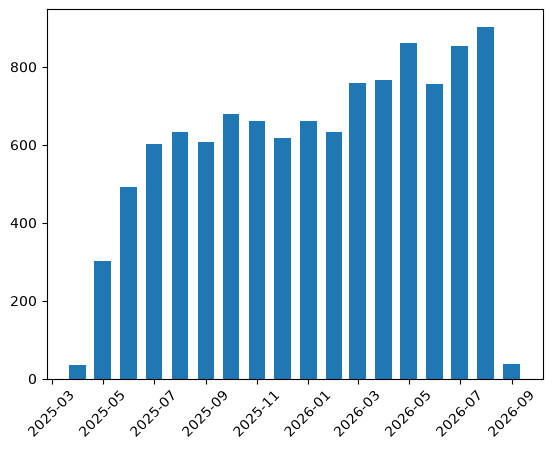

In [102]:
plt.bar(
    fraud_confirmation_by_month["fraud_confirmation_date"].dt.to_timestamp(),
    fraud_confirmation_by_month["count"],
    width=20
)

plt.xticks(rotation=45)
plt.show()

In [103]:
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


In [104]:
outcomes["fraud_evidence_type"].notnull().sum()

np.int64(10860)

In [105]:
outcomes.loc[outcomes["fraud_evidence_type"].notnull(), "fraud_evidence_type"].sample(25)

252453           verified_identity_theft_claim
404242           verified_identity_theft_claim
573269    substantiated_identity_investigation
654024           verified_identity_theft_claim
472374           verified_identity_theft_claim
325680    substantiated_identity_investigation
227293           verified_identity_theft_claim
714787           verified_identity_theft_claim
523480    substantiated_identity_investigation
2007             verified_identity_theft_claim
385331           verified_identity_theft_claim
531847    substantiated_identity_investigation
90327            verified_identity_theft_claim
414344    substantiated_identity_investigation
591994           verified_identity_theft_claim
635423           verified_identity_theft_claim
556575           verified_identity_theft_claim
33335     substantiated_identity_investigation
235633    substantiated_identity_investigation
633815    substantiated_identity_investigation
282499           verified_identity_theft_claim
504625    sub

In [106]:
outcomes["fraud_evidence_type"].value_counts(dropna=False)

fraud_evidence_type
NaN                                     764530
verified_identity_theft_claim             7324
substantiated_identity_investigation      3536
Name: count, dtype: int64

In [107]:
pd.crosstab(
    outcomes["confirmed_tpf_flag"], 
    outcomes["fraud_evidence_type"], 
    dropna=False, 
    
)

fraud_evidence_type,substantiated_identity_investigation,verified_identity_theft_claim,NaN
confirmed_tpf_flag,,,
0.0,0,0,490190
1.0,3536,7324,0
NaN,0,0,274340


In [108]:
3536 + 7324

10860

In [109]:
outcomes.columns

Index(['application_id', 'outcome_as_of_date', 'manual_review_flag',
       'review_started_date', 'review_completed_date',
       'manual_review_decision', 'step_up_type', 'step_up_result',
       'credit_decision', 'application_status', 'booked_flag', 'booking_date',
       'outcome_observation_end_date', 'days_on_book', 'tpf_outcome_status',
       'confirmed_tpf_flag', 'fraud_confirmation_date', 'fraud_evidence_type',
       'gross_fraud_loss_amount', 'fraud_recovery_amount', 'fraud_loss_amount',
       'currency', 'days_under_review (sw_created)'],
      dtype='str')

In [110]:
outcomes[["gross_fraud_loss_amount", "fraud_recovery_amount", "fraud_loss_amount"]].sample(25)

,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount
442265,0.0,0.0,0.0
563655,0.0,0.0,0.0
273417,0.0,0.0,0.0
337386,0.0,0.0,0.0
458096,0.0,0.0,0.0
713541,0.0,0.0,0.0
409561,0.0,0.0,0.0
231940,0.0,0.0,0.0
674580,0.0,0.0,0.0
351621,0.0,0.0,0.0


In [111]:
outcomes["currency"].value_counts()

currency
USD    775390
Name: count, dtype: int64

In [112]:
outcomes.dtypes

application_id                                str
outcome_as_of_date                 datetime64[us]
manual_review_flag                          int64
review_started_date                datetime64[us]
review_completed_date              datetime64[us]
manual_review_decision                        str
step_up_type                                  str
step_up_result                                str
credit_decision                               str
application_status                            str
booked_flag                                 int64
booking_date                       datetime64[us]
outcome_observation_end_date       datetime64[us]
days_on_book                              float64
tpf_outcome_status                            str
confirmed_tpf_flag                        float64
fraud_confirmation_date            datetime64[us]
fraud_evidence_type                           str
gross_fraud_loss_amount                   float64
fraud_recovery_amount                     float64


5.2 — Baseline Fraud Analysis Population
- Objective: Identify booked applications with sufficiently mature and observable fraud outcomes to establish a reliable baseline for evaluating the current fraud strategy.

In [113]:
outcomes.sample(10)

,application_id,outcome_as_of_date,manual_review_flag,review_started_date,review_completed_date,manual_review_decision,step_up_type,step_up_result,credit_decision,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirmed_tpf_flag,fraud_confirmation_date,fraud_evidence_type,gross_fraud_loss_amount,fraud_recovery_amount,fraud_loss_amount,currency,days_under_review (sw_created)
571846,10571847,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-04-17,2026-09-01,137.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
629422,10629423,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-05-29,2026-09-01,95.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
496079,10496080,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-03-01,2026-09-01,184.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
410342,10410343,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-01-02,2026-09-01,242.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
721303,10721304,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2026-07-27,2026-09-01,36.0,no_confirmed_tpf,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
153246,10153247,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-07-11,2026-09-01,417.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
253032,10253033,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,declined,credit_declined,0,NaT,NaT,NaN,not_observable,NaN,NaT,NaN,0.0,0.0,0.0,USD,NaT
174161,10174162,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-07-25,2026-09-01,403.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
86154,10086155,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-05-28,2026-09-01,461.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT
192861,10192862,2026-09-01,0,NaT,NaT,not_referred,none,not_applicable,approved,booked,1,2025-08-08,2026-09-01,389.0,no_confirmed_tpf,0.0,NaT,NaN,0.0,0.0,0.0,USD,NaT


In [114]:
find_optimal_population = outcomes[
    [
        "application_id",
        "outcome_as_of_date",
        "application_status",
        "booked_flag",
        "booking_date",
        "outcome_observation_end_date",
        "days_on_book",
        "tpf_outcome_status"
    ]
].copy()

In [115]:
find_optimal_population.sample(20)

,application_id,outcome_as_of_date,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status
426121,10426122,2026-09-01,booked,1,2026-01-12,2026-09-01,232.0,no_confirmed_tpf
515817,10515818,2026-09-01,booked,1,2026-03-12,2026-09-01,173.0,no_confirmed_tpf
177805,10177806,2026-09-01,credit_declined,0,NaT,NaT,NaN,not_observable
476341,10476342,2026-09-01,booked,1,2026-02-13,2026-09-01,200.0,no_confirmed_tpf
310885,10310886,2026-09-01,booked,1,2025-11-04,2026-09-01,301.0,no_confirmed_tpf
259764,10259765,2026-09-01,booked,1,2025-09-22,2026-09-01,344.0,no_confirmed_tpf
78921,10078922,2026-09-01,booked,1,2025-05-23,2026-09-01,466.0,no_confirmed_tpf
714881,10714882,2026-09-01,booked,1,2026-07-25,2026-09-01,38.0,no_confirmed_tpf
642074,10642075,2026-09-01,booked,1,2026-06-06,2026-09-01,87.0,no_confirmed_tpf
482066,10482067,2026-09-01,booked,1,2026-02-19,2026-09-01,194.0,no_confirmed_tpf


In [116]:
outcomes.columns

Index(['application_id', 'outcome_as_of_date', 'manual_review_flag',
       'review_started_date', 'review_completed_date',
       'manual_review_decision', 'step_up_type', 'step_up_result',
       'credit_decision', 'application_status', 'booked_flag', 'booking_date',
       'outcome_observation_end_date', 'days_on_book', 'tpf_outcome_status',
       'confirmed_tpf_flag', 'fraud_confirmation_date', 'fraud_evidence_type',
       'gross_fraud_loss_amount', 'fraud_recovery_amount', 'fraud_loss_amount',
       'currency', 'days_under_review (sw_created)'],
      dtype='str')

In [117]:
find_optimal_population["confirm_days_on_book"] = find_optimal_population["outcome_observation_end_date"] - find_optimal_population["booking_date"]

In [118]:
find_optimal_population["confirm_days_on_book"] = find_optimal_population["confirm_days_on_book"].dt.days

In [120]:
find_optimal_population["mature_90_days"] = (find_optimal_population["confirm_days_on_book"] > 90)

In [121]:
find_optimal_population.sample(10)

,application_id,outcome_as_of_date,application_status,booked_flag,booking_date,outcome_observation_end_date,days_on_book,tpf_outcome_status,confirm_days_on_book,mature_90_days
767679,10767680,2026-09-01,booking_pending,0,NaT,NaT,NaN,not_observable,NaN,False
96776,10096777,2026-09-01,booked,1,2025-06-08,2026-09-01,450.0,no_confirmed_tpf,450.0,True
685537,10685538,2026-09-01,booked,1,2026-07-05,2026-09-01,58.0,no_confirmed_tpf,58.0,False
296886,10296887,2026-09-01,booked,1,2025-10-19,2026-09-01,317.0,no_confirmed_tpf,317.0,True
151558,10151559,2026-09-01,booked,1,2025-07-11,2026-09-01,417.0,no_confirmed_tpf,417.0,True
33924,10033925,2026-09-01,booked,1,2025-04-23,2026-09-01,496.0,no_confirmed_tpf,496.0,True
546762,10546763,2026-09-01,offer_not_accepted,0,NaT,NaT,NaN,not_observable,NaN,False
21715,10021716,2026-09-01,booked,1,2025-04-17,2026-09-01,502.0,no_confirmed_tpf,502.0,True
225826,10225827,2026-09-01,booked,1,2025-08-28,2026-09-01,369.0,no_confirmed_tpf,369.0,True
459331,10459332,2026-09-01,booked,1,2026-02-03,2026-09-01,210.0,no_confirmed_tpf,210.0,True


In [122]:
total_applications = len(find_optimal_population)
total_applications

775390

In [123]:
total_mature_apps = find_optimal_population["mature_90_days"].sum()
total_mature_apps

np.int64(498743)

In [124]:
total_booked_apps = (find_optimal_population["booked_flag"].sum())
total_booked_apps

np.int64(603829)

In [125]:
find_optimal_population["booked_flag"].value_counts()

booked_flag
1    603829
0    171561
Name: count, dtype: int64

In [126]:
print(f"Total Applications: {total_applications}")
print(f"Total Booked Applications: {total_booked_apps}")
print(f"Total Mature Applications (>90 Days on Book): {total_mature_apps}")

Total Applications: 775390
Total Booked Applications: 603829
Total Mature Applications (>90 Days on Book): 498743


In [127]:
# Percentage of applications that are more than 90 days mature 
total_book_percentage = (total_mature_apps / total_booked_apps)
print(f"Percentage of booked applications that are at least 90 days mature: {total_book_percentage:.2%}")


Percentage of booked applications that are at least 90 days mature: 82.60%


In [128]:
find_optimal_population.columns

Index(['application_id', 'outcome_as_of_date', 'application_status',
       'booked_flag', 'booking_date', 'outcome_observation_end_date',
       'days_on_book', 'tpf_outcome_status', 'confirm_days_on_book',
       'mature_90_days'],
      dtype='str')

In [129]:
find_optimal_population["tpf_outcome_status"] = outcomes["tpf_outcome_status"]

In [130]:
find_optimal_population.columns

Index(['application_id', 'outcome_as_of_date', 'application_status',
       'booked_flag', 'booking_date', 'outcome_observation_end_date',
       'days_on_book', 'tpf_outcome_status', 'confirm_days_on_book',
       'mature_90_days'],
      dtype='str')

In [131]:
find_optimal_population.loc[find_optimal_population["mature_90_days"], "tpf_outcome_status"].value_counts()

tpf_outcome_status
no_confirmed_tpf         489069
confirmed_tpf              9622
investigation_pending        52
Name: count, dtype: int64

In [132]:
pd.crosstab(find_optimal_population["mature_90_days"], find_optimal_population["tpf_outcome_status"])

tpf_outcome_status,confirmed_tpf,investigation_pending,no_confirmed_tpf,not_observable
mature_90_days,,,,
False,1238,720,103128,171561
True,9622,52,489069,0


In [133]:
outcomes.columns

Index(['application_id', 'outcome_as_of_date', 'manual_review_flag',
       'review_started_date', 'review_completed_date',
       'manual_review_decision', 'step_up_type', 'step_up_result',
       'credit_decision', 'application_status', 'booked_flag', 'booking_date',
       'outcome_observation_end_date', 'days_on_book', 'tpf_outcome_status',
       'confirmed_tpf_flag', 'fraud_confirmation_date', 'fraud_evidence_type',
       'gross_fraud_loss_amount', 'fraud_recovery_amount', 'fraud_loss_amount',
       'currency', 'days_under_review (sw_created)'],
      dtype='str')

In [136]:
# Lets now create our baseline population to work with. Use original outcomes dataframe

# booked_flag == 1
# mature_90_days == True
# tpf_outcome_status is either confirmed_tpf or no_confirmed_tpf

baseline_population = (find_optimal_population.loc[(find_optimal_population["booked_flag"])
                            & (find_optimal_population["mature_90_days"]) 
                            & (find_optimal_population["tpf_outcome_status"].isin(["confirmed_tpf", "no_confirmed_tpf"]))
            ]
).copy()

In [137]:
baseline_population.count()

application_id                  498691
outcome_as_of_date              498691
application_status              498691
booked_flag                     498691
booking_date                    498691
outcome_observation_end_date    498691
days_on_book                    498691
tpf_outcome_status              498691
confirm_days_on_book            498691
mature_90_days                  498691
dtype: int64

In [138]:
498743 - 498691

52